# Dual FEG: convergence discovery

Let $A$ be monotone and $L$-Lipschitz on a real finite-dimensional Euclidean space, with $L>0$, $R\geq0$, integer $N\geq1$, $A(x_\star)=0$, and $\|x_{0}-x_\star\|^2\leq R^2$. Set $z_{0}=0$ and $\alpha=1/L$. For $k=0,\ldots,N-1$,
$$x_{k+1/2}=x_{k}-\alpha z_{k}-\alpha A(x_{k}),$$
$$x_{k+1}=x_{k+1/2}-\frac{N-k-1}{N-k}\alpha\bigl(A(x_{k+1/2})-A(x_{k})\bigr),$$
$$z_{k+1}=\frac{N-k-1}{N-k}z_{k}-\frac{A(x_{k+1/2})}{N-k}.$$
We select the terminal squared residual $\|A(x_{N})\|^2$ as metric. Pairwise monotonicity and Lipschitz constraints give a valid PEP relaxation; interpolation sufficiency is not assumed.

## Proof Statement

### Theorem

Under the assumptions and update rule above, for every integer $N\geq1$,
$$\boxed{\|A(x_{N})\|^{2}\leq\frac{4L^{2}R^{2}}{N^{2}}.}$$
Let $a=A(x_{N})$. Define the horizon-dependent potential
$$
V_{k}=-4\langle a,z_{k}\rangle-2\|z_{k}\|^{2}
+\frac{4L}{N-k}\langle a+z_{k},x_{k}-x_{N}\rangle
-\frac{4L}{N}\langle a,x_{0}-x_{N}\rangle,\quad 0\leq k<N,
$$
and
$$V_{N}=2\|a\|^{2}-\frac{4L}{N}\langle a,x_{0}-x_{N}\rangle.$$
Then $V_{0}=0$ and $V_{k+1}\leq V_{k}$ for every $0\leq k<N$. This is an a posteriori certificate: it is allowed to depend on the terminal point.


### Proof outline

Write $y_{k}=x_{k+1/2}$, $a=A(x_{N})$, and $t=N-k$. The potential used here is
$$V_{k}=-4\langle a,z_{k}\rangle-2\|z_{k}\|^{2}
+\frac{4L}{t}\langle a+z_{k},x_{k}-x_{N}\rangle
-\frac{4L}{N}\langle a,x_{0}-x_{N}\rangle\quad(k<N),$$
with $V_{N}=2\|a\|^{2}-(4L/N)\langle a,x_{0}-x_{N}\rangle$. Define
$$H_{k}=\|A(x_{k})-A(y_{k})\|^{2}-L^{2}\|x_{k}-y_{k}\|^{2}\leq0,$$
$$M_{k}=-\langle a-A(y_{k}),x_{N}-y_{k}\rangle\leq0.$$
The first inequality is Lipschitz continuity and the second is monotonicity.

For $0\leq k\leq N-2$, substitution of the three algorithm updates gives the exact identity
$$V_{k+1}-V_{k}=\frac{2}{t^{2}}H_{k}+\frac{4L}{t(t-1)}M_{k}\leq0.$$
Here $t\geq2$, so both multipliers are positive. At the last step, $x_{N}=y_{N-1}$ and
$$V_{N}-V_{N-1}=2\left(\|A(x_{N-1})-a\|^{2}-L^{2}\|x_{N-1}-x_{N}\|^{2}\right)\leq0.$$
Since $z_{0}=0$, the two anchor terms in $V_{0}$ cancel. Thus $V_{N}\leq V_{0}=0$. When $N=1$, the interior range is empty; the same base and final-step identities apply.

Finally let $d=x_{0}-x_{\star}$ and $M_{\star}=-\langle a,x_{N}-x_{\star}\rangle\leq0$. The exact boundary identity is
$$
\|a\|^{2}-\frac{4L^{2}}{N^{2}}\|d\|^{2}
=V_{N}+\frac{4L}{N}M_{\star}
-\left\|a-\frac{2L}{N}d\right\|^{2}\leq0.
$$
The last inequality uses $V_{N}\leq0$, monotonicity with $A(x_{\star})=0$, and nonnegativity of a squared norm. Apply $\|d\|^{2}\leq R^{2}$. No division by $R$ is used, so $R=0$ is included. This proves the theorem.


In [1]:
import json
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

NOTEBOOK_DIR = Path.cwd()
REPO_ROOT = NOTEBOOK_DIR / "supplementary" / "approved"
sys.path[:0] = [str(REPO_ROOT), str(NOTEBOOK_DIR / "supplementary"), str(NOTEBOOK_DIR)]


In [2]:
import pepflow as pf
import sympy as sp
print("Framework origin:", pf.__file__)

Framework origin: C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\dual_feg\r05\supplementary\approved\pepflow\__init__.py


## Operator and parameters

In [3]:
L = pf.Parameter("L")
A = pf.LipschitzMonotoneOperator(is_basis=True, tags=["A"], L=L)




## Algorithm and PEP setup

In [4]:
def make_ctx_dual_feg(ctx_name: str, N, **kwargs) -> pf.PEPContext:
    ctx = pf.PEPContext(ctx_name).set_as_current()
    x = pf.Vector(is_basis=True, tags=["x_0"])
    A.set_zero_point("x_star")
    z = pf.Vector.zero().add_tag("z_0")
    for k in range(int(N)):
        a = A(x)
        a.add_tag(f"a_{k}")
        y = (x - z / L - a / L).add_tag(f"y_{k}")
        b = A(y)
        b.add_tag(f"b_{k}")
        q = sp.Rational(int(N) - k - 1, int(N) - k)
        x = (y - q * (b - a) / L).add_tag(f"x_{k + 1}")
        z = (q * z - b / (int(N) - k)).add_tag(f"z_{k + 1}")
    A(x).add_tag(f"a_{N}")
    return ctx


def get_pep_setup(N, params):
    R = pf.Parameter("R")
    ctx = make_ctx_dual_feg(f"ctx_{N}", N)
    pb = pf.PEPBuilder(ctx)
    pb.add_initial_constraint(
        ((ctx["x_0"] - ctx["x_star"]) ** 2).le(R**2, name="initial_condition")
    )
    pb.set_performance_metric(A(ctx[f"x_{N}"]) ** 2)
    return ctx, pb, A


In [5]:
ctx_check, pb_check, operator_check = get_pep_setup(2, {"L": 1, "R": 1})
assert ctx_check["z_0"].equiv_by_randomness(pf.Vector.zero())
print("Setup constructed; z_0 is zero.")

Setup constructed; z_0 is zero.


## Numerical evidence

N=1: 1.9999999321, optimal_inaccurate
N=2: 0.9999999977, optimal
N=3: 0.4444444512, optimal
N=4: 0.2500000015, optimal
N=5: 0.1600000034, optimal
N=6: 0.1111111136, optimal
N=7: 0.0816326559, optimal
Maximum absolute fit residual for N>=2: 6.736229074544298e-09


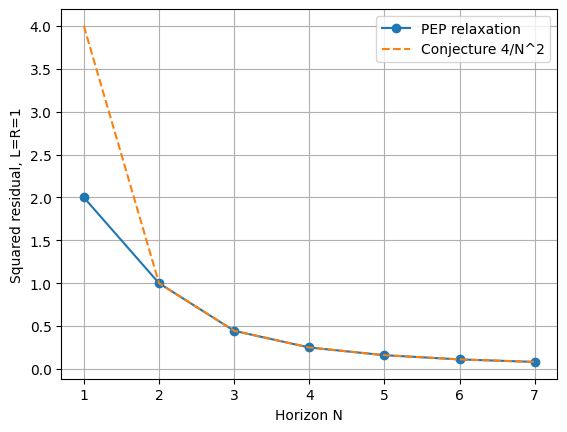

In [6]:
state = json.loads((NOTEBOOK_DIR / "state" / "dual_feg_b1.json").read_text())
rows = state["sweep_results"]
for row in rows:
    print(f"N={row['N']}: {row['opt_value']:.10f}, {row['status']}")
ns = np.array([row["N"] for row in rows])
values = np.array([row["opt_value"] for row in rows])
candidate = 4.0 / ns**2
print("Maximum absolute fit residual for N>=2:", np.max(np.abs(values[1:] - candidate[1:])))
plt.plot(ns, values, "o-", label="PEP relaxation")
plt.plot(ns, candidate, "--", label="Conjecture 4/N^2")
plt.xlabel("Horizon N")
plt.ylabel("Squared residual, L=R=1")
plt.legend()
plt.grid(True)
plt.show()

The data suggest $\|A(x_{N})\|^2\leq4L^2R^2/N^2$. At $N=1$ the numerical value is approximately $2L^2R^2$ and the status is optimal_inaccurate. Remaining sweep statuses are optimal. Numerical evidence is not an arbitrary-horizon proof.

## Full PEP certificate
The selected certificate uses the normalized sample $L=R=1$, $N=6$. Dense and sparse primal SDPs were solved with CLARABEL defaults. All selected duals and the Gram remainder come from one sparse solve.

In [7]:
dense = json.loads((NOTEBOOK_DIR / "state/dual_feg_dense.json").read_text())
certificate = json.loads((NOTEBOOK_DIR / "state/dual_feg_b2.json").read_text())
print("Dense bound:", dense["opt_value"], dense["solver_status"])
print("Selected sparse bound:", certificate["opt_value"], certificate["solver_status"])
print("Basis:", certificate["basis_vectors"])
print("Dropped constraints:", len(certificate["relaxed_constraints"]))
print("Preserved-optimum gap:", abs(dense["opt_value"] - certificate["opt_value"]))
for data, label in [(dense, "dense"), (certificate, "sparse")]:
    for group in sorted({m["group"] for m in data["constraint_metadata"].values() if m["group"]}):
        entries = [(n, v) for n, v in data["named_dual_values"].items()
                   if data["constraint_metadata"][n]["group"] == group and v is not None and abs(v) > 1e-6]
        print(label, group, "significant terms:", entries)
for data,label in [(dense,"dense"),(certificate,"selected sparse")]:
    for family in sorted({m["group"] for m in data["constraint_metadata"].values() if m["group"]}):
        significant = [(name,val) for name,val in data["named_dual_values"].items()
                       if data["constraint_metadata"][name]["group"]==family and val is not None and abs(val)>1e-6]
        print(label,family,"labeled significant duals; display cutoff 1e-6 only.")
        pf.pprint_labeled_matrix(np.array([[v] for _,v in significant]),
            row_labels=[name for name,_ in significant],column_labels=["dual"],precision=8)


Dense bound:

 0.11111111362413659 optimal
Selected sparse bound: 0.11111111056378391 optimal
Basis: ['x_0', 'x_star', 'a_0', 'b_0', 'a_1', 'b_1', 'a_2', 'b_2', 'a_3', 'b_3', 'a_4', 'b_4', 'a_5', 'b_5', 'a_6']
Dropped constraints: 170
Preserved-optimum gap: 3.0603526796069147e-09
dense Lipschitz Continuous Inequality significant terms: [('A Lipschitz:x_0,y_0', 0.055555568994121986), ('A Lipschitz:x_1,y_1', 0.08000001871723995), ('A Lipschitz:x_2,y_2', 0.12500002369537433), ('A Lipschitz:x_3,y_3', 0.22222225573517132), ('A Lipschitz:x_4,y_4', 0.5000000629702696), ('A Lipschitz:x_5,x_6', 1.9999329727117232), ('A Lipschitz:x_5,y_5', 6.730908141310188e-05), ('A Lipschitz:x_6,y_5', 0.5469806649803577)]
dense Monotone Operator Inequality significant terms: [('A monotone:x_6,x_star', 0.6666277784084684), ('A monotone:x_6,y_0', 0.13332569958931756), ('A monotone:x_6,y_1', 0.19998701512125716), ('A monotone:x_6,y_2', 0.3333098711409026), ('A monotone:x_6,y_3', 0.6666366868202113), ('A monotone:x_6,y_4', 1.99

<IPython.core.display.Math object>

dense Monotone Operator Inequality labeled significant duals; display cutoff 1e-6 only.


<IPython.core.display.Math object>

selected sparse Lipschitz Continuous Inequality labeled significant duals; display cutoff 1e-6 only.


<IPython.core.display.Math object>

selected sparse Monotone Operator Inequality labeled significant duals; display cutoff 1e-6 only.


<IPython.core.display.Math object>

### Sparse pattern and initial formula search
Keep terminal-point monotonicity against $x_\star$ and $y_{k}=x_{k+1/2}$ for $0\leq k<N-1$, and Lipschitz constraints between $x_{k},y_{k}$ for $k<N-1$, with the final pair $x_{N-1},x_{N}$. All others are dropped. The final auxiliary evaluation at $y_{N-1}=x_{N}$ is not required by this relaxation.

Rational inspection suggests terminal-star multiplier $4/N$, terminal-$y_{k}$ multiplier $4/[(N-k)(N-k-1)]$, and Lipschitz multiplier $2/(N-k)^2$. These are normalized-sample candidates. The initial multiplier is $4/N^2$.

The low-rank remainder suggests
$$S_{\rm guess}=\left\|\frac{2}{N}(x_{0}-x_\star)-A(x_{N})\right\|^2.$$
No target references were consulted. Numerical comparisons do not establish these formulas for arbitrary horizons.

In [8]:
N_cert = certificate["N"]
ctx_cert, pb_cert, A_cert = get_pep_setup(N_cert, {"L": 1, "R": 1})
pm_cert = pf.ExpressionManager(ctx_cert, resolve_parameters={"L": sp.Integer(1), "R": sp.Integer(1)})
lambda_guess = {"initial_condition": 4/N_cert**2, f"A monotone:x_{N_cert},x_star": 4/N_cert}
lambda_guess.update({f"A monotone:x_{N_cert},y_{k}": 4/((N_cert-k)*(N_cert-k-1)) for k in range(N_cert-1)})
lambda_guess.update({f"A Lipschitz:x_{k},y_{k}": 2/(N_cert-k)**2 for k in range(N_cert-1)})
lambda_guess[f"A Lipschitz:x_{N_cert-1},x_{N_cert}"] = 2
active_names = [n for n,v in certificate["named_dual_values"].items() if v is not None]
lambda_error = max(abs(lambda_guess[n]-certificate["named_dual_values"][n]) for n in active_names)
pf.pprint_labeled_matrix(np.array([[lambda_guess[n]] for n in active_names]), row_labels=active_names, column_labels=["candidate"])
print("Candidate lambda maximum error:", lambda_error)
assert lambda_error <= 1e-4
S_array = np.asarray(certificate["S_matrix"])
w_guess = 2/N_cert*(ctx_cert["x_0"]-ctx_cert["x_star"])-A_cert(ctx_cert[f"x_{N_cert}"])
S_guess_eval = pm_cert.eval_scalar(w_guess**2)
S_guess = np.asarray(S_guess_eval.inner_prod_coords, dtype=float)
print("S candidate error:", np.max(np.abs(S_guess-S_array)))
assert np.allclose(S_guess, S_array, atol=1e-4, rtol=1e-5)
assert np.max(np.abs(S_guess_eval.func_coords), initial=0) == 0
assert S_guess_eval.offset == 0
support = [0, 1, len(certificate["basis_vectors"])-1]
pf.pprint_labeled_matrix(S_guess[np.ix_(support,support)], row_labels=[certificate["basis_vectors"][i] for i in support])
print("Candidate S has no other nonzero coordinates.")

<IPython.core.display.Math object>

Candidate lambda maximum error: 2.0027061521155076e-05
S candidate error: 2.002695544300881e-05


<IPython.core.display.Math object>

Candidate S has no other nonzero coordinates.


### Selected numerical decomposition
Reverse LDL preserves the complete saved remainder, including small pivots. No pivot or multiplier has been discarded from the certificate.

In [9]:
pf.pprint_labeled_matrix(S_array,row_labels=certificate["basis_vectors"],column_labels=certificate["basis_vectors"])
D = np.asarray(certificate["numerical_decomposition"]["D"])
E = np.asarray(certificate["numerical_decomposition"]["ell_coords"])
print("Reverse LDL diagonal:", np.diag(D))
print("Selected S rank at tolerance 1e-4:", np.linalg.matrix_rank(S_array, tol=1e-4))
pf.pprint_labeled_matrix(E, row_labels=[f"ell_{i}" for i in range(len(E))], column_labels=certificate["basis_vectors"])
print("S reconstruction maximum error:", np.max(np.abs(E.T@D@E-S_array)))
assert np.allclose(E.T@D@E, S_array, atol=1e-4, rtol=1e-5)

<IPython.core.display.Math object>

Reverse LDL diagonal: [9.99979973e-01 5.66428127e-10 4.80638875e-10 4.90625555e-10
 5.39407243e-10 7.43139197e-10 5.04717637e-10 7.14136984e-10
 4.95109854e-10 7.70385297e-10 4.76556282e-10 7.14925983e-10
 4.66926385e-10 6.33269125e-10 6.26214116e-10]
Selected S rank at tolerance 1e-4: 1


<IPython.core.display.Math object>

S reconstruction maximum error: 2.7755575615628914e-17


### Complete numerical certificate check
For every retained scalar constraint let $r_{c}\leq0$ be its normalized residual. The certificate identity is
$$\mathrm{metric}-\mathrm{bound}-\sum_{c}\lambda_{c} r_{c}+S=0.$$
The following cell rebuilds every residual from the setup, checks its stored coordinates, and checks Gram, function and constant components. It also verifies the signs and positive semidefiniteness required for the bound.

In [10]:
entries = list(pb_cert.init_conditions) + A_cert.get_interpolation_constraints(ctx_cert)
assert {c.name for c in entries} == set(certificate["named_dual_values"])
weighted = pf.Scalar.zero()
for constraint in entries:
    name = constraint.name
    meta = certificate["constraint_metadata"][name]
    value = certificate["named_dual_values"][name]
    residual = constraint.lhs-constraint.rhs
    if constraint.cmp.value in ("GE", "SEQ"):
        residual = -residual
    evaluated = pm_cert.eval_scalar(pf.Scalar.zero()+residual)
    saved = certificate["constraint_coordinates"][name]
    assert np.allclose(evaluated.inner_prod_coords, saved["gram"], atol=1e-12, rtol=0)
    assert np.allclose(evaluated.func_coords, saved["func"], atol=1e-12, rtol=0)
    assert abs(float(evaluated.offset)-saved["offset"]) <= 1e-12
    if meta["relaxed"]:
        assert value is None
    else:
        assert value is not None and np.isfinite(value) and value >= -1e-6
        weighted += value * (pf.Scalar.zero()+residual)
basis_cert = ctx_cert.basis_vectors()
S_numeric = sum((float(S_array[i,j])*basis_cert[i]*basis_cert[j]
                 for i,j in np.ndindex(S_array.shape)), pf.Scalar.zero())
checked = pm_cert.eval_scalar(pb_cert.performance_metric-certificate["opt_value"]-weighted+S_numeric)
residuals = [float(np.max(np.abs(checked.inner_prod_coords))),
             float(np.max(np.abs(checked.func_coords),initial=0)),
             abs(float(checked.offset))]
print("Gram/function/offset identity residuals:", residuals)
pf.pprint_labeled_matrix(np.asarray(checked.inner_prod_coords, dtype=float), row_labels=certificate["basis_vectors"])
assert max(residuals) <= 1e-5
assert np.isfinite(S_array).all() and np.allclose(S_array,S_array.T,atol=1e-6,rtol=0)
assert np.linalg.eigvalsh(S_array).min() >= -1e-6
assert certificate["solver_status"] == "optimal"
assert abs(certificate["opt_value"]-dense["opt_value"]) <= 1e-5
assert abs(certificate["opt_value"]-4/N_cert**2) <= 1e-5
print("Numerical certificate verified; analytic full-PEP and Lyapunov proofs remain unverified.")

Gram/function/offset identity residuals: [1.866268550956371e-09, 0.0, 6.914619710141068e-10]


<IPython.core.display.Math object>

Numerical certificate verified; analytic full-PEP and Lyapunov proofs remain unverified.


## Lyapunov partial sums

Write $y_{k}=x_{k+1/2}$ and use normalized residuals
$$M_{k}=-\langle A(x_{N})-A(y_{k}),x_{N}-y_{k}\rangle\leq0,\qquad
H_{k}=\|A(x_{k})-A(y_{k})\|^2-\|x_{k}-y_{k}\|^2\leq0.$$
At $L=1$, the selected numerical multipliers define
$$V_{0}=0,\qquad V_{k+1}-V_{k}=\lambda_{k} M_{k}+\mu_{k} H_{k}\quad(0\leq k<N-1).$$
The final increment is the selected Lipschitz residual between $x_{N-1}$ and $x_{N}$ with its multiplier. Every increment is nonpositive. Keep terminal-star monotonicity and the whole nonnegative $S$ as boundary leftovers. Using the entire saved remainder avoids replacing small numerical components by the rank-one candidate.

Reconstruction and coverage include all Gram, function, and constant components. The same construction has interior rank four at both tested horizons; this is discovery evidence rather than an all-horizon theorem.

In [11]:
import hashlib
import json
from pathlib import Path
import numpy as np
import pepflow as pf
import sympy as sp
ROOT = NOTEBOOK_DIR
CERTIFICATE_KEYS = ('N_verify', 'params_json', 'relaxed_constraints', 'S_matrix', 'S_row_names', 'S_col_names', 'basis_vectors', 'basis_scalars', 'opt_value', 'tau_sol', 'tau_name', 'named_dual_values', 'constraint_metadata', 'normalization', 'certificate_provenance', 'numerical_checks', 'numerical_decomposition')
def recheck(certificate):
    payload = {k: certificate[k] for k in CERTIFICATE_KEYS}
    digest = hashlib.sha256(json.dumps(payload, sort_keys=True, separators=(",", ":"), allow_nan=False).encode()).hexdigest()
    assert digest == certificate["certificate_id"]
    for p, h in certificate["certificate_provenance"]["source_hashes"].items():
        source = (ROOT / p).resolve()
        assert source.is_relative_to(ROOT)
        assert hashlib.sha256(source.read_bytes()).hexdigest() == h
    assert Path(pf.__file__).resolve() == ROOT / "supplementary/approved/pepflow/__init__.py"
    assert certificate["certificate_provenance"]["pep_type"] == "primal"
    assert certificate["solver_status"] == "optimal"
    assert certificate["closed_form_search"]["completed"]
    N = certificate["N_verify"]
    params = {str(k): sp.Rational(v) for k,v in json.loads(certificate["params_json"]).items()}
    ctx, pb, obj = get_pep_setup(N, params)
    pb.set_relaxed_constraints(certificate["relaxed_constraints"])
    pm = pf.ExpressionManager(ctx, resolve_parameters={k: v for k,v in params.items()})
    assert [str(v) for v in ctx.basis_vectors()] == certificate["basis_vectors"] == certificate["S_row_names"] == certificate["S_col_names"]
    assert [str(v) for v in ctx.basis_scalars()] == certificate["basis_scalars"]
    groups = ctx.get_constraint_data(obj)
    assert not groups.psd_dict and not ctx.func_to_triplets
    records = [(c, "initial", None, None) for c in pb.init_conditions]
    records += [(c, "interpolation", str(obj), str(g)) for g, cs in groups.sc_dict.items() for c in cs]
    assert len(records) == len({c.name for c,*_ in records})
    assert {c.name for c,*_ in records} == set(certificate["named_dual_values"]) == set(certificate["constraint_metadata"])
    terms = {}
    for c, origin, owner, group in records:
        meta = {"origin":origin, "owner":owner, "group":group, "kind":"scalar",
                "comparator":c.cmp.value, "shape":[], "relaxed":c.name in pb.relaxed_constraints}
        assert meta == certificate["constraint_metadata"][c.name]
        val = certificate["named_dual_values"][c.name]
        residual = c.lhs-c.rhs
        if c.cmp.value in ("GE", "SEQ"):
            residual = -residual
        e = pm.eval_scalar(pf.Scalar.zero()+residual)
        coords = certificate["constraint_coordinates"][c.name]
        assert np.allclose(e.inner_prod_coords, coords["gram"], atol=1e-12, rtol=0)
        assert np.allclose(e.func_coords, coords["func"], atol=1e-12, rtol=0)
        assert abs(float(e.offset)-coords["offset"]) <= 1e-12
        if meta["relaxed"]:
            assert val is None
        else:
            assert val is not None and np.isfinite(val) and (c.cmp.value == "EQ" or val >= -1e-6)
            terms[c.name] = val*(pf.Scalar.zero()+residual)
    assert set(pb.relaxed_constraints).issubset(certificate["constraint_metadata"])
    assert certificate["normalization"]["tau_name"] == certificate["tau_name"] == "initial_condition"
    assert certificate["normalization"]["bound_value"] == certificate["opt_value"]
    assert certificate["named_dual_values"]["initial_condition"] == certificate["tau_sol"]
    S = np.asarray(certificate["S_matrix"])
    assert np.isfinite(S).all() and np.allclose(S,S.T,atol=1e-6,rtol=0)
    assert np.linalg.eigvalsh(S).min() >= -1e-6
    dec = certificate["numerical_decomposition"]
    E,D = np.asarray(dec["ell_coords"]),np.asarray(dec["D"])
    assert dec["basis_labels"] == certificate["basis_vectors"]
    assert np.allclose(E.T@D@E,S,atol=1e-4,rtol=1e-5)
    basis = ctx.basis_vectors()
    S_scalar = sum((float(S[i,j])*basis[i]*basis[j] for i,j in np.ndindex(S.shape)),pf.Scalar.zero())
    diff = pm.eval_scalar(pb.performance_metric-certificate["opt_value"]-sum(terms.values(),pf.Scalar.zero())+S_scalar)
    residuals = [float(np.max(np.abs(diff.inner_prod_coords))),float(np.max(np.abs(diff.func_coords),initial=0)),abs(float(diff.offset))]
    assert max(residuals) <= 1e-5
    return ctx,pb,obj,pm,terms,S_scalar,residuals

ctx,pb,obj,pm,weighted_terms,S_scalar,certificate_residuals = recheck(certificate)
certificate_checked = True
N_int = certificate['N_verify']


C:\Users\Jack\Documents\GitHub\PEPFlow\examples_peppy\_evaluations\20260923T140754Z_paper5_pgm_sos_6x5_isolation1\dual_feg\r05\supplementary\approved\pepflow\pep_context.py:172: UserWarning:

The provided name was already used. The older PEPContext will be overwritten. PEPBuilders constructed with the older PEPContext should be remade.



In [12]:
S_piece_terms = {"whole_S": S_scalar}
S_assignment = {"whole_S": "boundary"}
S_check = pm.eval_scalar(S_scalar)
assert np.max(np.abs(S_check.func_coords), initial=0) == 0
assert S_check.offset == 0
assert np.linalg.eigvalsh(np.asarray(S_check.inner_prod_coords, dtype=float)).min() >= -1e-6


In [13]:
def group(certificate):
    ctx,pb,obj,pm,terms,S_scalar,residuals = recheck(certificate)
    N = certificate["N_verify"]
    term_assignment = {}
    group_terms = {n:v for n,v in terms.items() if n!="initial_condition"}
    for name in group_terms:
        if name == f"A monotone:x_{N},x_star":
            term_assignment[name] = "boundary"
        elif name.startswith("A monotone:"):
            term_assignment[name] = int(name.split(",y_")[1])
        elif name == f"A Lipschitz:x_{N-1},x_{N}":
            term_assignment[name] = N-1
        else:
            term_assignment[name] = int(name.split(",y_")[1])
    S_piece_terms = {"whole_S":S_scalar}
    S_assignment = {name: "boundary" for name in S_piece_terms}
    lyap = [pf.Scalar.zero()]
    partial_sum = pf.Scalar.zero()
    for k in range(N):
        partial_sum += sum((v for n,v in group_terms.items() if term_assignment[n] == k),pf.Scalar.zero())
        lyap.append(partial_sum)
    evaluated = [pm.eval_scalar(v) for v in lyap]
    matrices = [np.asarray(v.inner_prod_coords,dtype=float) for v in evaluated]
    svs = [np.linalg.svd(M,compute_uv=False) for M in matrices]
    ranks = [int(np.count_nonzero(s>1e-4)) for s in svs]
    boundary = sum((v for n,v in group_terms.items() if term_assignment[n]=="boundary"),pf.Scalar.zero())-S_scalar
    coverage = pm.eval_scalar(lyap[N]+boundary-(sum(group_terms.values(),pf.Scalar.zero())-S_scalar))
    coverage_res = [float(np.max(np.abs(coverage.inner_prod_coords))),float(np.max(np.abs(coverage.func_coords),initial=0)),abs(float(coverage.offset))]
    assert max(coverage_res)<=1e-5
    for k in range(N):
        inc=sum((v for n,v in group_terms.items() if term_assignment[n]==k),pf.Scalar.zero())
        chk=pm.eval_scalar(lyap[k+1]-lyap[k]-inc)
        assert np.max(np.abs(chk.inner_prod_coords))<=1e-5
        assert np.max(np.abs(chk.func_coords),initial=0)<=1e-5 and abs(float(chk.offset))<=1e-5
    assert sum(v=="boundary" for v in term_assignment.values())<=1
    report = {"N":N, "certificate_id":certificate["certificate_id"], "recipe_id":"forward_lip_mon_terminal_whole_S_boundary",
        "rank_profile":ranks, "singular_values":[s.tolist() for s in svs],
        "rank_convention":{"tolerance":1e-4,"scaling":"unscaled Gram matrix","coordinate_order":"setup basis, earlier iterates first"},
        "rank_credible":bool(all(not np.any((s>=5e-5)&(s<=2e-4)) for s in svs)),
        "certificate_checked":True,"grouping_checked":True,
        "identity_residuals":residuals,"coverage_residuals":coverage_res,
        "constraint_assignment":term_assignment,"S_assignment":S_assignment,
        "lyap_inner_prod_coords":[m.tolist() for m in matrices],
        "lyap_func_coords":[np.asarray(v.func_coords,dtype=float).tolist() for v in evaluated],
        "lyap_offsets":[float(v.offset) for v in evaluated]}
    return report

observation = group(certificate)
grouping_checked = observation["grouping_checked"]
ranks = observation["rank_profile"]
lyap = []
for coords, fcoords, offset in zip(observation["lyap_inner_prod_coords"], observation["lyap_func_coords"], observation["lyap_offsets"]):
    value = sum((float(coords[i][j])*ctx.basis_vectors()[i]*ctx.basis_vectors()[j] for i,j in np.ndindex(np.shape(coords))), pf.Scalar.zero())
    assert len(fcoords) == 0
    lyap.append(value + offset)

for k,rank in enumerate(ranks):
    print(f"rank V_{k}: {rank}")
    if k == 0:
        print()
rank_left = rank_right = 1
retained = ranks[rank_left:N_int+1-rank_right]
print("Interior rank is constant at this N:", len(retained)>=3 and len(set(retained))==1, "boundary exclusions:", (rank_left,rank_right))
print("Full-coordinate coverage residuals:", observation["coverage_residuals"])


rank V_0: 0

rank V_1: 4
rank V_2: 4
rank V_3: 4
rank V_4: 4
rank V_5: 4
rank V_6: 2
Interior rank is constant at this N: True boundary exclusions: (1, 1)
Full-coordinate coverage residuals: [8.867120650477239e-17, 0.0, 0.0]


In [14]:
rank_samples = []
for cert_path in [NOTEBOOK_DIR/"state/dual_feg_b2.json", NOTEBOOK_DIR/"supplementary/certificate_N8.json"]:
    sample_certificate = json.loads(cert_path.read_text())
    rank_samples.append(group(sample_certificate))
retained_profiles = [sample["rank_profile"][1:sample["N"]] for sample in rank_samples]
assert all(len(profile)>=3 and len(set(profile))==1 for profile in retained_profiles)
assert len({profile[0] for profile in retained_profiles})==1
assert all(sample["rank_credible"] and sample["certificate_checked"] and sample["grouping_checked"] for sample in rank_samples)
print("Confirmed horizons:", [sample["N"] for sample in rank_samples])
print("Common interior rank:", retained_profiles[0][0])
print("Fixed exclusions: V_0 and V_N; absolute rank tolerance 1e-4, unscaled Gram coordinates.")
print("Each sample includes checked certificate, coverage, and singular-value evidence.")
# Restore selected context after the independent confirmation sample.
ctx,pb,obj,pm,weighted_terms,S_scalar,certificate_residuals = recheck(certificate)

Confirmed horizons: [6, 8]
Common interior rank: 4
Fixed exclusions: V_0 and V_N; absolute rank tolerance 1e-4, unscaled Gram coordinates.
Each sample includes checked certificate, coverage, and singular-value evidence.


## Identify the vectors composing the Lyapunov function
We start from the verified partial sums. Interior indices are $1\leq k\leq N-1$; both endpoints remain required reconstruction cases.

In [15]:
from pepflow.lyapunov_utils import vectors_in_column_space, find_basis_with_sparsest_coefficients, find_symmetric_coefficient_matrix
b3 = json.loads((NOTEBOOK_DIR/"state/dual_feg_b3.json").read_text())
certificate = b3
observation = group(certificate)
ctx,pb,obj,pm,weighted_terms,S_scalar,certificate_residuals = recheck(certificate)
ctx.set_as_current()
N_int = certificate["N_verify"]
params_sp = {"L":sp.Integer(1),"R":sp.Integer(1)}
basis = ctx.basis_vectors()
lyap = [sum((float(coords[i][j])*basis[i]*basis[j] for i,j in np.ndindex(np.shape(coords))),pf.Scalar.zero())+offset
        for coords,offset in zip(observation["lyap_inner_prod_coords"],observation["lyap_offsets"])]
assert observation["rank_profile"] == b3["rank_profile"]
assert b3["rank_search"]["boundary_exclusions"] == {"left":1,"right":1}
for k,V in enumerate(lyap):
    evaluated = pm.eval_scalar(V)
    assert np.allclose(evaluated.inner_prod_coords,b3["lyap_inner_prod_coords"][k],atol=1e-4,rtol=1e-5)
    assert np.allclose(evaluated.func_coords,b3["lyap_func_coords"][k],atol=1e-4,rtol=1e-5)
    assert abs(float(evaluated.offset)-b3["lyap_offsets"][k]) <= 1e-4
print("Rebuilt every selected partial sum; interior rank four, endpoints zero and two.")

Rebuilt every selected partial sum; interior rank four, endpoints zero and two.


### Candidate-vector scan
Candidates include all tagged iterates, auxiliary vectors and operator outputs, plus current-to-terminal and initial-to-terminal gaps. Duplicate coordinate vectors and zero vectors are removed.

In [16]:
candidate_pairs_by_k = {}
for k in range(1,N_int+1):
    pairs=[("A_N",obj(ctx[f"x_{N_int}"])),(f"z_{k}",ctx[f"z_{k}"]),
           (f"x_{k}-x_N",ctx[f"x_{k}"]-ctx[f"x_{N_int}"]),
           ("x_0-x_N",ctx["x_0"]-ctx[f"x_{N_int}"]),
           (f"x_{k}-x_0",ctx[f"x_{k}"]-ctx["x_0"])]
    for i in range(N_int+1):
        for prefix in ["x","z","a"]:
            pairs.append((f"{prefix}_{i}",ctx[f"{prefix}_{i}"]))
    for i in range(N_int):
        for prefix in ["y","b"]:
            pairs.append((f"{prefix}_{i}",ctx[f"{prefix}_{i}"]))
    pairs += [(f"x_{i}-x_N",ctx[f"x_{i}"]-ctx[f"x_{N_int}"]) for i in range(N_int)]
    unique = []
    seen = []
    for label,vector in pairs:
        coordinates = np.asarray(pm.eval_vector(vector).coords,dtype=float)
        if np.linalg.norm(coordinates)<=1e-12 or any(np.allclose(coordinates,v,atol=1e-12,rtol=0) for v in seen):
            continue
        unique.append((label,vector))
        seen.append(coordinates)
    candidate_pairs_by_k[k] = unique

In [17]:
filtered_by_k = {}
labels_by_k = {}
for k,pairs in candidate_pairs_by_k.items():
    labels_by_k[k] = {id(v):label for label,v in pairs}
    inside = vectors_in_column_space(lyap[k],[v for _,v in pairs],pep_context=ctx,
        resolve_parameters={n:v for n,v in params_sp.items()},atol=1e-4,rtol=1e-4)
    filtered_by_k[k] = inside
    print(f"V_{k} column-space candidates:")
    for v in inside:
        print("   "+labels_by_k[k][id(v)])

V_1 column-space candidates:


   A_N
   z_1
   x_1-x_N
   x_0-x_N
   x_1-x_0
   a_0
   b_0
V_2 column-space candidates:
   A_N
   z_2
   x_2-x_N
   x_0-x_N
   x_2-x_0
V_3 column-space candidates:
   A_N
   z_3
   x_3-x_N
   x_0-x_N
   x_3-x_0
V_4 column-space candidates:
   A_N
   z_4
   x_4-x_N
   x_0-x_N
   x_4-x_0
V_5 column-space candidates:
   A_N
   z_5
   x_5-x_N
   x_0-x_N
   x_5-x_0
   a_5
V_6 column-space candidates:
   A_N
   x_0-x_N
   x_6-x_0


### Selected basis pattern

In [18]:
sparse_bases = {}
sparse_coefficients = {}
for k,inside in filtered_by_k.items():
    chosen,C = find_basis_with_sparsest_coefficients(lyap[k],inside,pep_context=ctx,
        resolve_parameters={n:v for n,v in params_sp.items()},
        zero_tol=1e-6,indep_tol=1e-7,span_tol=1e-5)
    sparse_bases[k] = chosen
    sparse_coefficients[k] = C
    print(f"k={k}, rank {b3['rank_profile'][k]}")
    print("  sparse basis:", [labels_by_k[k][id(v)] for v in chosen])
    print(f"  zero coefficients: {np.count_nonzero(np.abs(C)<1e-6)}/{C.size}")

k=1, rank 4
  sparse basis: ['A_N', 'z_1', 'x_1-x_N', 'x_0-x_N']
  zero coefficients: 7/16
k=2, rank 4
  sparse basis: ['A_N', 'z_2', 'x_2-x_N', 'x_0-x_N']
  zero coefficients: 7/16
k=3, rank 4
  sparse basis: ['A_N', 'z_3', 'x_3-x_N', 'x_0-x_N']
  zero coefficients: 7/16
k=4, rank 4
  sparse basis: ['A_N', 'z_4', 'x_4-x_N', 'x_0-x_N']
  zero coefficients: 7/16
k=5, rank 4
  sparse basis: ['A_N', 'x_5-x_N', 'x_0-x_N', 'a_5']
  zero coefficients: 10/16
k=6, rank 2
  sparse basis: ['A_N', 'x_0-x_N']
  zero coefficients: 1/4


The sparse search differs at $k=N-1$. We adopt the following consistent independent template to expose the auxiliary recurrence; its reconstruction is checked below:
$$\mathcal B_{k}=(A(x_{N}),z_{k},x_{k}-x_{N},x_{0}-x_{N}),\qquad 1\leq k<N.$$
At $k=0$ the basis is empty. At $k=N$ use $(A(x_{N}),x_{0}-x_{N})$.

In [19]:
def V_k_basis(k):
    if k == 0:
        return []
    if k == N_int:
        return [obj(ctx[f"x_{N_int}"]), ctx["x_0"]-ctx[f"x_{N_int}"]]
    return [obj(ctx[f"x_{N_int}"]), ctx[f"z_{k}"],
            ctx[f"x_{k}"]-ctx[f"x_{N_int}"], ctx["x_0"]-ctx[f"x_{N_int}"]]

def V_k_basis_labels(k):
    if k == 0:
        return []
    if k == N_int:
        return ["A_N", "x_0-x_N"]
    return ["A_N", f"z_{k}", f"x_{k}-x_N", "x_0-x_N"]

for k in range(N_int+1):
    vectors = V_k_basis(k)
    rank = int(np.linalg.matrix_rank(np.column_stack([pm.eval_vector(v).coords for v in vectors]).astype(float),tol=1e-7)) if vectors else 0
    assert rank == len(vectors) == b3["rank_profile"][k]
    print(f"k={k}: rank {rank} basis {V_k_basis_labels(k)}")


k=0: rank 0 basis []
k=1: rank 4 basis ['A_N', 'z_1', 'x_1-x_N', 'x_0-x_N']
k=2: rank 4 basis ['A_N', 'z_2', 'x_2-x_N', 'x_0-x_N']
k=3: rank 4 basis ['A_N', 'z_3', 'x_3-x_N', 'x_0-x_N']
k=4: rank 4 basis ['A_N', 'z_4', 'x_4-x_N', 'x_0-x_N']
k=5: rank 4 basis ['A_N', 'z_5', 'x_5-x_N', 'x_0-x_N']
k=6: rank 2 basis ['A_N', 'x_0-x_N']


### Coefficient matrices
Use the displayed basis order and the convention $V_{k}=\sum_{i,j}C_{ij}\langle v_{i},v_{j}\rangle$. The off-diagonal entries contribute twice. Function and constant terms are verified absent.

In [20]:
def V_k_structure(k):
    vectors=V_k_basis(k)
    C=coeff_by_k[k]
    return sum((float(C[i,j])*vectors[i]*vectors[j] for i,j in np.ndindex(C.shape)),pf.Scalar.zero())

coeff_by_k = {}
for k in range(N_int+1):
    vectors = V_k_basis(k)
    C = find_symmetric_coefficient_matrix(lyap[k],vectors,pep_context=ctx,
        resolve_parameters={n:v for n,v in params_sp.items()},indep_tol=1e-7,span_tol=1e-5)
    coeff_by_k[k] = C
    diff = pm.eval_scalar(V_k_structure(k)-lyap[k])
    target = pm.eval_scalar(lyap[k])
    error = float(np.linalg.norm(np.asarray(diff.inner_prod_coords,dtype=float),ord="fro"))
    scale = max(1.0,float(np.linalg.norm(np.asarray(target.inner_prod_coords,dtype=float),ord="fro")))
    assert error <= 1e-5*scale
    assert np.max(np.abs(diff.func_coords),initial=0) <= 1e-5
    assert abs(float(diff.offset)) <= 1e-5
    assert np.max(np.abs(target.func_coords),initial=0) == 0 and target.offset == 0
    print(f"k={k}: reconstruction residual {error:.3e}; function terms absent, offset zero.")
    if C.size:
        pf.pprint_labeled_matrix(C,row_labels=V_k_basis_labels(k),column_labels=V_k_basis_labels(k))


k=0: reconstruction residual 0.000e+00; function terms absent, offset zero.


k=1: reconstruction residual 2.781e-16; function terms absent, offset zero.

<IPython.core.display.Math object>

k=2: reconstruction residual 8.422e-10; function terms absent, offset zero.

<IPython.core.display.Math object>

k=3: reconstruction residual 1.246e-09; function terms absent, offset zero.


... (3 outputs left out)

k=5: reconstruction residual 2.162e-09; function terms absent, offset zero.

<IPython.core.display.Math object>

k=6: reconstruction residual 3.274e-09; function terms absent, offset zero.


<IPython.core.display.Math object>

In [21]:
def coeff_pattern(k, N):
    if k == 0:
        return np.zeros((0,0))
    if k == N:
        return np.array([[2, -2/N],[-2/N,0]])
    t=N-k
    return np.array([[0,-2,2/t,-2/N],[-2,-2,2/t,0],
                     [2/t,2/t,0,0],[-2/N,0,0,0]])

for k,C in coeff_by_k.items():
    candidate = coeff_pattern(k,N_int)
    if candidate.size:
        pf.pprint_labeled_matrix(candidate,row_labels=V_k_basis_labels(k),column_labels=V_k_basis_labels(k))
    error = float(np.max(np.abs(candidate-C),initial=0))
    assert error <= 1e-4
    print(f"k={k}: candidate coefficient error {error:.3e}")
other = json.loads((NOTEBOOK_DIR/"supplementary/certificate_N8.json").read_text())
obs8 = group(other)
ctx8,pb8,obj8,pm8,_,_,_ = recheck(other)
ctx8.set_as_current()
for k in range(9):
    vectors = [] if k==0 else ([obj8(ctx8["x_8"]),ctx8["x_0"]-ctx8["x_8"]] if k==8 else
        [obj8(ctx8["x_8"]),ctx8[f"z_{k}"],ctx8[f"x_{k}"]-ctx8["x_8"],ctx8["x_0"]-ctx8["x_8"]])
    B = np.column_stack([pm8.eval_vector(v).coords for v in vectors]).astype(float) if vectors else np.zeros((len(ctx8.basis_vectors()),0))
    error = np.max(np.abs(B@coeff_pattern(k,8)@B.T-np.asarray(obs8["lyap_inner_prod_coords"][k])),initial=0)
    assert error <= 1e-4
    print(f"N=8, k={k}: candidate expression error {error:.3e}")
ctx.set_as_current()


k=0: candidate coefficient error 0.000e+00


<IPython.core.display.Math object>

k=1: candidate coefficient error 2.017e-05


<IPython.core.display.Math object>

k=2: candidate coefficient error 2.009e-05


<IPython.core.display.Math object>

... (4 outputs left out)

k=5: candidate coefficient error 2.003e-05


<IPython.core.display.Math object>

k=6: candidate coefficient error 2.003e-05


N=8, k=0: candidate expression error 0.000e+00
N=8, k=1: candidate expression error 9.877e-07
N=8, k=2: candidate expression error 2.304e-06
N=8, k=3: candidate expression error 4.148e-06
N=8, k=4: candidate expression error 6.912e-06
N=8, k=5: candidate expression error 1.152e-05
N=8, k=6: candidate expression error 2.073e-05
N=8, k=7: candidate expression error 4.838e-05
N=8, k=8: candidate expression error 5.529e-05


### Block 4 conclusion
For $L=1$ the numerical data suggest, with $a=A(x_{N})$ and $t=N-k$,
$$V_{k}=-4\langle a,z_{k}\rangle-2\|z_{k}\|^2+\frac4t\langle a+z_{k},x_{k}-x_{N}\rangle-\frac4N\langle a,x_{0}-x_{N}\rangle,\quad 0\leq k<N,$$
$$V_{N}=2\|a\|^2-\frac4N\langle a,x_{0}-x_{N}\rangle.$$
The formula gives $V_{0}=0$. All selected numerical partial sums reconstruct, including endpoints, and the candidate fits both tested horizons. These are candidate formulas, not an analytic proof. Block 5 must handle general $L$, exact step and terminal identities, signs, and the final normalization.

## Exact coefficient formulas and symbolic contexts

Restoring the parameter $L$ multiplies each iterate-gap coefficient by $L$. In the ordered interior basis $(a,z_{k},x_{k}-x_{N},x_{0}-x_{N})$, the exact coefficient matrix is
$$C_{k}=\begin{pmatrix}0&-2&2L/(N-k)&-2L/N\\-2&-2&2L/(N-k)&0\\2L/(N-k)&2L/(N-k)&0&0\\-2L/N&0&0&0\end{pmatrix}.$$
The terminal matrix on $(a,x_{0}-x_{N})$ is $\begin{pmatrix}2&-2L/N\\-2L/N&0\end{pmatrix}$, and $V_{0}=0$. These reuse the numerical candidate's structure. The exact identities below establish the formulas over their full domain. No function-value or constant terms occur.

In [22]:
from typing import Any

b4 = json.loads((NOTEBOOK_DIR/"state/dual_feg_b4.json").read_text())
assert b4["numerical_reconstruction"]["certificate_id"] == b4["certificate_id"]
assert b4["numerical_reconstruction"]["passed"]
print("Discovery certificate:", b4["certificate_id"])
print("Analytic proof is now checked symbolically, independently of numerical tolerances.")

def potential(t, x, z, a, x_initial, x_terminal, horizon, smoothness):
    return (-4*a*z - 2*z**2
            + 4*smoothness/t*(a+z)*(x-x_terminal)
            - 4*smoothness/horizon*a*(x_initial-x_terminal))

def exact_components(expression, manager):
    value = manager.eval_scalar(pf.Scalar.zero()+expression, sympy_mode=True)
    G = sp.Matrix(value.inner_prod_coords).applyfunc(sp.simplify)
    F = sp.Matrix(list(value.func_coords)).applyfunc(sp.simplify)
    c = sp.simplify(sp.sympify(value.offset))
    return G,F,c

def exact_check(label, expression, manager):
    G,F,c = exact_components(expression,manager)
    pf.pprint_labeled_matrix(np.asarray(G.tolist(),dtype=object),
        row_labels=[str(v) for v in manager.context.basis_vectors()])
    print(label, "function residual:", F, "constant residual:", c)
    assert all(v == 0 for v in [*G,*F,c]), label
    print(label, "exact identity verified.")
    return {"gram_zero": True, "function_zero": True, "offset_zero": True}


Discovery certificate: edf49e9fee44adacb6a7c8251d2ea6f1bd9aa85b6d46c24f285867dff2fb0d45
Analytic proof is now checked symbolically, independently of numerical tolerances.


In [23]:
k_formula,N_formula = sp.symbols("k N",integer=True)
L_formula = sp.Symbol("L",positive=True)
C_formula = sp.Matrix([[0,-2,2*L_formula/(N_formula-k_formula),-2*L_formula/N_formula],
    [-2,-2,2*L_formula/(N_formula-k_formula),0],
    [2*L_formula/(N_formula-k_formula),2*L_formula/(N_formula-k_formula),0,0],
    [-2*L_formula/N_formula,0,0,0]])
pf.pprint_labeled_matrix(np.asarray(C_formula.tolist(),dtype=object),
    row_labels=["a","z_{k}","x_{k}-x_{N}","x_{0}-x_{N}"],precision=0)
print("Coefficient domain: L>0, integers N>=1 and 0<k<N.")

<IPython.core.display.Math object>

Coefficient domain: L>0, integers N>=1 and 0<k<N.


## Symbolic Step Recursion Verification

For $t=N-k\geq2$, verify
$$V_{k+1}-V_{k}=\frac{2}{t^{2}}\left(\|A(x_{k})-A(y_{k})\|^{2}-L^{2}\|x_{k}-y_{k}\|^{2}\right)-\frac{4L}{t(t-1)}\langle a-A(y_{k}),x_{N}-y_{k}\rangle.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must be zero in every scalar coordinate. The context keeps $N,t,L$ symbolic and substitutes the actual updates.

In [24]:
ctx_step = pf.PEPContext("dual_feg_symbolic_step").set_as_current()
ell = pf.Parameter("ell")
t = pf.Parameter("t")
horizon = pf.Parameter("horizon")
L_symbol = sp.Symbol("L", positive=True)
t_symbol = sp.Symbol("t", integer=True, positive=True)
N_symbol = sp.Symbol("N", integer=True, positive=True)
symbolic_parameters: dict[str, Any] = {"ell":L_symbol,"t":t_symbol,"horizon":N_symbol}
A_step = pf.LipschitzMonotoneOperator(is_basis=True,tags=["A_{step}"],L=ell)
x_step = pf.Vector(is_basis=True,tags=["x_{k}"])
z_step = pf.Vector(is_basis=True,tags=["z_{k}"])
x0_step = pf.Vector(is_basis=True,tags=["x_{0}"])
xN_step = pf.Vector(is_basis=True,tags=["x_{N}"])
g_step = A_step(x_step)
a_step = A_step(xN_step)
y_step = (x_step-(z_step+g_step)/ell).add_tag("y_{k}")
b_step = A_step(y_step)
x_next = y_step-(t-1)/t*(b_step-g_step)/ell
z_next = (t-1)/t*z_step-b_step/t
V_step = potential(t,x_step,z_step,a_step,x0_step,xN_step,horizon,ell)
V_next = potential(t-1,x_next,z_next,a_step,x0_step,xN_step,horizon,ell)
I_lip = (g_step-b_step)**2-ell**2*(x_step-y_step)**2
I_mon = -(a_step-b_step)*(xN_step-y_step)
LHS_step = V_next-V_step
RHS_step = 2/t**2*I_lip+4*ell/(t*(t-1))*I_mon
diff_step = LHS_step-RHS_step
pm_step = pf.ExpressionManager(ctx_step,resolve_parameters=symbolic_parameters)
step_check = exact_check("Interior step (t>=2)",diff_step,pm_step)


<IPython.core.display.Math object>

Interior step (t>=2) function residual: Matrix(0, 0, []) constant residual: 0
Interior step (t>=2) exact identity verified.


## Base Case and Boundary Symbolic Verification

For every $N\geq1$, verify $V_{0}=0$ by substituting $x=x_{0}$, $z_{0}=0$, and $t=N$. The residual $\mathrm{LHS}-\mathrm{RHS}$ must vanish exactly. This calculation does not substitute into the singular terminal formula.

In [25]:
ctx_base = pf.PEPContext("dual_feg_symbolic_base").set_as_current()
x0_base = pf.Vector(is_basis=True,tags=["x_{0}"])
xN_base = pf.Vector(is_basis=True,tags=["x_{N}"])
A_base = pf.LipschitzMonotoneOperator(is_basis=True,tags=["A_{base}"],L=ell)
a_base = A_base(xN_base)
z0_base = pf.Vector.zero()
LHS_base = potential(horizon,x0_base,z0_base,a_base,x0_base,xN_base,horizon,ell)
RHS_base = pf.Scalar.zero()
diff_base = LHS_base-RHS_base
pm_base = pf.ExpressionManager(ctx_base,resolve_parameters=symbolic_parameters)
base_check = exact_check("Base (N>=1, z_0=0)",diff_base,pm_base)


<IPython.core.display.Math object>

Base (N>=1, z_0=0) function residual: Matrix(0, 0, []) constant residual: 0
Base (N>=1, z_0=0) exact identity verified.


### Final-Step Identity Symbolic Verification

The update with $t=1$ gives $x_{N}=x_{N-1}-(z_{N-1}+A(x_{N-1}))/L$. Verify
$$V_{N}-V_{N-1}=2\left(\|A(x_{N-1})-A(x_{N})\|^{2}-L^{2}\|x_{N-1}-x_{N}\|^{2}\right).$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must vanish. This also covers $N=1$.

In [26]:
ctx_last = pf.PEPContext("dual_feg_symbolic_last_step").set_as_current()
x_last = pf.Vector(is_basis=True,tags=["x_{N-1}"])
z_last = pf.Vector(is_basis=True,tags=["z_{N-1}"])
x0_last = pf.Vector(is_basis=True,tags=["x_{0}"])
A_last = pf.LipschitzMonotoneOperator(is_basis=True,tags=["A_{last}"],L=ell)
g_last = A_last(x_last)
xN_last = (x_last-(z_last+g_last)/ell).add_tag("x_{N}")
a_last = A_last(xN_last)
V_penultimate = potential(1,x_last,z_last,a_last,x0_last,xN_last,horizon,ell)
V_terminal = 2*a_last**2-4*ell/horizon*a_last*(x0_last-xN_last)
LHS_last = V_terminal-V_penultimate
RHS_last = 2*((g_last-a_last)**2-ell**2*(x_last-xN_last)**2)
diff_last = LHS_last-RHS_last
pm_last = pf.ExpressionManager(ctx_last,resolve_parameters=symbolic_parameters)
last_check = exact_check("Final step (including N=1)",diff_last,pm_last)


<IPython.core.display.Math object>

Final step (including N=1) function residual: Matrix(0, 0, []) constant residual: 0
Final step (including N=1) exact identity verified.


### Boundary Identity Symbolic Verification

Using $a=A(x_{N})$, $d=x_{0}-x_{\star}$, and $A(x_{\star})=0$, verify
$$\|a\|^{2}-\frac{4L^{2}}{N^{2}}\|d\|^{2}
=V_{N}-\frac{4L}{N}\langle a,x_{N}-x_{\star}\rangle-\left\|a-\frac{2L}{N}d\right\|^{2}.$$
The residual $\mathrm{LHS}-\mathrm{RHS}$ must vanish in Gram, function, and constant components.

In [27]:
ctx_boundary = pf.PEPContext("dual_feg_symbolic_boundary").set_as_current()
x0_boundary = pf.Vector(is_basis=True,tags=["x_{0}"])
xN_boundary = pf.Vector(is_basis=True,tags=["x_{N}"])
A_boundary = pf.LipschitzMonotoneOperator(is_basis=True,tags=["A_{boundary}"],L=ell)
xstar_boundary = A_boundary.set_zero_point("x_{star}")
a_boundary = A_boundary(xN_boundary)
d_boundary = x0_boundary-xstar_boundary
V_boundary = 2*a_boundary**2-4*ell/horizon*a_boundary*(x0_boundary-xN_boundary)
M_boundary = -a_boundary*(xN_boundary-xstar_boundary)
square_boundary = (a_boundary-2*ell/horizon*d_boundary)**2
LHS_boundary = a_boundary**2-4*ell**2/horizon**2*d_boundary**2
RHS_boundary = V_boundary+4*ell/horizon*M_boundary-square_boundary
diff_boundary = LHS_boundary-RHS_boundary
pm_boundary = pf.ExpressionManager(ctx_boundary,resolve_parameters=symbolic_parameters)
boundary_check = exact_check("Metric boundary and normalization",diff_boundary,pm_boundary)



<IPython.core.display.Math object>

Metric boundary and normalization function residual: Matrix(0, 0, []) constant residual: 0
Metric boundary and normalization exact identity verified.


### Signs, domain, and conclusion

Interior denominators satisfy $t\geq2$ and $t-1\geq1$. With $L>0$, $N\geq1$, the multipliers $2/t^{2}$, $4L/[t(t-1)]$, $2$, and $4L/N$ are positive. Lipschitz and monotone residuals are nonpositive, and the boundary square is nonnegative in a real Euclidean space. Hence
$$V_{N}\leq V_{0}=0,\qquad \|A(x_{N})\|^{2}\leq\frac{4L^{2}}{N^{2}}\|x_{0}-x_{\star}\|^{2}\leq\frac{4L^{2}R^{2}}{N^{2}}.$$
All identities hold for arbitrary dimension and horizon. The numerical full-PEP certificate remains recorded separately; no independent universal global multiplier-table verification is claimed.

In [28]:
positive_remaining = sp.Symbol("m", integer=True, positive=True)
positive_horizon = sp.Symbol("n", integer=True, positive=True)
positive_L = sp.Symbol("ell_positive", positive=True)
assert (sp.Rational(2)/(positive_remaining+1)**2).is_positive
assert (4*positive_L/((positive_remaining+1)*positive_remaining)).is_positive
assert (4*positive_L/positive_horizon).is_positive
assert (4*positive_L**2/positive_horizon**2).is_positive
proof_checks = {
    "step":all(step_check.values()) and all(last_check.values()),
    "base":all(base_check.values()), "boundary":all(boundary_check.values()),
    "signs":True, "domain":True, "normalization":True}
assert all(proof_checks.values())
print("All exact identities verified.")
print("Positive multipliers on L>0, N>=1, t>=2; final multiplier 2.")
print("V_N <= V_0 = 0 and ||A(x_N)||^2 <= 4 L^2 ||x_0-x_star||^2/N^2 <= 4 L^2 R^2/N^2.")
print("Numerical certificate: verified. Analytic Lyapunov proof: verified.")
print("Global full-PEP formula status: not separately certified.")


All exact identities verified.
Positive multipliers on L>0, N>=1, t>=2; final multiplier 2.
V_N <= V_0 = 0 and ||A(x_N)||^2 <= 4 L^2 ||x_0-x_star||^2/N^2 <= 4 L^2 R^2/N^2.
Numerical certificate: verified. Analytic Lyapunov proof: verified.
Global full-PEP formula status: not separately certified.
